In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df= pd.read_csv('Position_Salaries.csv')
df.head(10)

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [5]:
df.shape

(10, 3)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Position  10 non-null     object
 1   Level     10 non-null     int64 
 2   Salary    10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 372.0+ bytes


In [7]:
df.describe()

,Level,Salary
count,10.00000,10.000000
mean,5.50000,249500.000000
std,3.02765,299373.883668
min,1.00000,45000.000000
25%,3.25000,65000.000000
50%,5.50000,130000.000000
75%,7.75000,275000.000000
max,10.00000,1000000.000000


In [8]:
df.isnull().sum()

,0
Position,0
Level,0
Salary,0


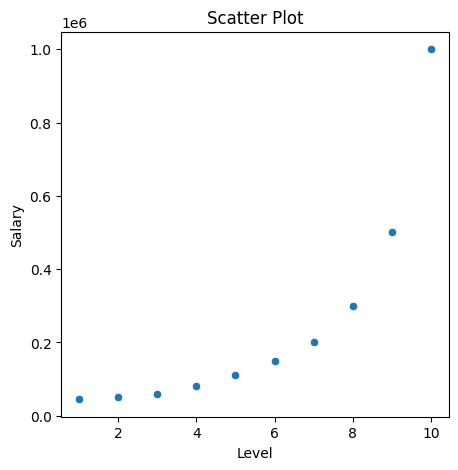

In [10]:
plt.figure(figsize=(5,5))
sns.scatterplot(x='Level',y='Salary',data=df)
plt.title('Scatter Plot')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.show()



In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [15]:
X=df[["Level"]]
y= df["Salary"]

In [16]:
poly= PolynomialFeatures()


In [17]:
X_poly =poly.fit_transform(X)
print(X_poly)

[[  1.   1.   1.]
 [  1.   2.   4.]
 [  1.   3.   9.]
 [  1.   4.  16.]
 [  1.   5.  25.]
 [  1.   6.  36.]
 [  1.   7.  49.]
 [  1.   8.  64.]
 [  1.   9.  81.]
 [  1.  10. 100.]]


In [18]:
poly_model= LinearRegression()
poly_model.fit(X_poly,y)

LinearRegression()

In [19]:
y_poly_pred= poly_model.predict(X_poly)

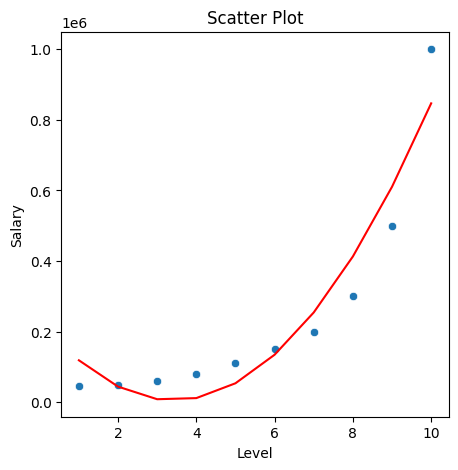

In [20]:
plt.figure(figsize=(5,5))
sns.scatterplot(x='Level',y='Salary',data=df)
plt.plot(X,y_poly_pred,color='red')
plt.title('Scatter Plot')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.show()

In [21]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
poly_r2= r2_score(y,y_poly_pred)
poly_mse= mean_squared_error(y,y_poly_pred)
poly_mae= mean_absolute_error(y,y_poly_pred)
print("R2 Score: ",poly_r2)
print("Mean Squared Error: ",poly_mse)
print("Mean Absolute Error: ",poly_mae)

R2 Score:  0.9162082221443942
Mean Squared Error:  6758833333.333338
Mean Absolute Error:  70218.1818181819
